# A Primer on UQ in Machine Learning and Finance - UQ in financial forecasting
### From GARCH to adaptive conformal prediction

**Goal.** Suppose we have a model that predicts how much an asset may fluctuate tomorrow. How can we quantify the uncertainty of that prediction? And what happens if the market suddenly becomes more volatile?

By the end of this exercise, you will be able to interpret a GARCH forecast, construct a conformal prediction interval, identify a calibration failure under distribution shift, and update the interval online as new information arrives.

*Source:* Gibbs & Candès (2024), [Conformal Inference for Online Prediction with Arbitrary Distribution Shifts](https://jmlr.org/papers/v25/22-1218.html)

In [51]:
# Run once

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

# Visual style inspired by the lecture slides.
plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True,
                     "grid.alpha": 0.18, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
RED = "#B01C2E"
BLUE = "#27658A"
GREY = "#675E61"
TEAL = "#167D79"

## 1. Our financial problem

Let $P_t$ denote the price of an asset at the end of trading day $t$. Its simple daily return is

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}.$$

We store returns in percentage points, $R_t=100r_t$. Thus $R_t=-2$ means a loss of 2% that day.

Instead of trying to predict whether the market will go up or down, we will forecast the **size of its fluctuations**. Following the paper, our target is the squared return

$$V_t=R_t^2.$$

For example, a return of $-2\%$ gives $V_t=4$ (percentage points squared). Both positive and negative large moves matter. Squared returns are noisy observations used as a proxy for conditional variance; they are **not** the latent volatility itself.

We create a synthetic market with a calm initial period, a sudden high-volatility regime (inspired by the sort of disruption seen during financial crises), and a return to calmer conditions. These are not historical stock prices. We know the regime dates because we simulate them; the forecasting and calibration algorithms will not use those dates.

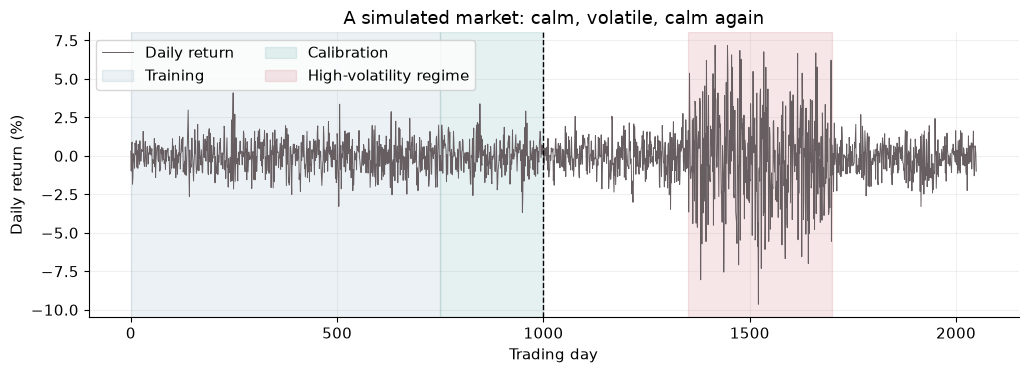

In [52]:
# Generate an artificial market with a reproducible random seed.
# The model below is used only to generate data; the fitted model will not
# be given these parameters or the regime labels.
rng = np.random.default_rng(42)
N_TRAIN, N_CAL, N_STABLE, N_CRISIS, N_RECOVERY = 750, 250, 350, 350, 350
TEST_START = N_TRAIN + N_CAL
CRISIS_START = TEST_START + N_STABLE
RECOVERY_START = CRISIS_START + N_CRISIS
N = RECOVERY_START + N_RECOVERY
days = np.arange(N)

base = np.zeros(N)
true_h = np.zeros(N)
true_h[0] = 1.0
base[0] = np.sqrt(true_h[0]) * rng.normal()
for t in range(1, N):
    true_h[t] = 0.08 + 0.10 * base[t-1]**2 + 0.82 * true_h[t-1]
    base[t] = np.sqrt(true_h[t]) * rng.normal()

scale = np.ones(N)
scale[CRISIS_START:RECOVERY_START] = 3.0   # three times the usual return scale
returns = scale * base                     # R_t, in percentage points
V = returns**2                              # V_t, squared return

# Display the timeline. The coloured areas are for explanation only.
fig, ax = plt.subplots(figsize=(12, 3.7))
ax.plot(days, returns, color=GREY, linewidth=0.7, label="Daily return")
ax.axvspan(0, N_TRAIN-0.5, color=BLUE, alpha=0.09, label="Training")
ax.axvspan(N_TRAIN-0.5, TEST_START-0.5, color=TEAL, alpha=0.11, label="Calibration")
ax.axvspan(CRISIS_START-0.5, RECOVERY_START-0.5, color=RED, alpha=0.11,
           label="High-volatility regime")
ax.axvline(TEST_START-0.5, color="black", linestyle="--", linewidth=1)
ax.set(title="A simulated market: calm, volatile, calm again",
       xlabel="Trading day", ylabel="Daily return (%)")
ax.legend(ncol=2, loc="upper left")
plt.show()

### Why split the data in time?

We use three consecutive blocks. The **training set** estimates the GARCH parameters (750 days). The **calibration set** measures forecast errors (250 days). The **test set** evaluates one-day-ahead predictions: 350 calm days, 350 volatile days and 350 recovery days. At each test day the forecast must be made before that day's return is observed. We never randomly shuffle financial time series.

## 2. GARCH: a simple model of market volatility

**GARCH** stands for *Generalised Autoregressive Conditional Heteroskedasticity*. The idea is that volatility changes through time: large price movements often cluster together.

A zero-mean GARCH(1,1) model writes

$$R_t=\sigma_t\varepsilon_t,\qquad \varepsilon_t\sim\mathcal N(0,1),$$

$$\underbrace{\sigma_t^2}_{\text{variance forecast}}=\omega+aR_{t-1}^2+b\sigma_{t-1}^2.$$

Here $\omega>0$ is a baseline variance contribution, $a\geq0$ controls how strongly recent squared returns affect the forecast, and $b\geq0$ controls persistence of past volatility. We impose $a+b<1$ during fitting.

The next-day expected return is zero in this simplified model. Its useful prediction is instead $\widehat v_t=\widehat\sigma_t^2$, an estimate of the conditional expected squared return. GARCH is widely used in risk management, volatility forecasting and financial econometrics because it models volatility clustering.

### 2.1. The functions we need

The first function below implements the recursion. The second estimates $\omega,a,b$ using the training data by minimising the Gaussian negative log-likelihood (up to constants),

$$\frac{1}{2n}\sum_{t=1}^n\left(\log\sigma_t^2+\frac{R_t^2}{\sigma_t^2}\right).$$

SciPy performs the numerical optimisation. The Gaussian assumption is used **for fitting the baseline**; we do not use Gaussian quantiles to construct our conformal intervals. The details of the optimiser are not required for the exercise.

In [53]:
def garch_variance(r, params, initial_var):
    """Return one-step-ahead conditional variance forecasts for a return series."""
    omega, a, b = params
    h = np.zeros(len(r))
    h[0] = initial_var
    for t in range(1, len(r)):
        # Only yesterday's observed return and variance forecast are used.
        h[t] = omega + a * r[t-1]**2 + b * h[t-1]
    return h


def fit_garch(r_train):
    """Fit the three GARCH parameters using the training period only."""
    initial_var = np.var(r_train)

    def loss(params):
        h = garch_variance(r_train, params, initial_var)
        return 0.5 * np.mean(np.log(h) + r_train**2 / h)

    result = minimize(loss, x0=[0.1 * initial_var, 0.08, 0.85],
                      method="SLSQP",
                      bounds=[(1e-6, None), (0, 0.999), (0, 0.999)],
                      constraints=[{"type": "ineq", "fun": lambda p: 0.999-p[1]-p[2]}],
                      options={"maxiter": 300, "ftol": 1e-10})
    if not result.success:
        raise RuntimeError(result.message)
    return result.x, initial_var

### 2.2. Fit the model and make forecasts

We estimate the parameters once, using only the training set. Then we forecast sequentially: although the parameters remain fixed, the conditional variance updates every day as yesterday's return becomes known. Keeping the model fixed helps us isolate the effect of different uncertainty-calibration methods. In the original paper the authors refit GARCH on a rolling window of 1,250 days; our smaller exercise is deliberately simpler.

Fitted GARCH: omega = 0.155, a = 0.164, b = 0.672
Persistence a + b = 0.836


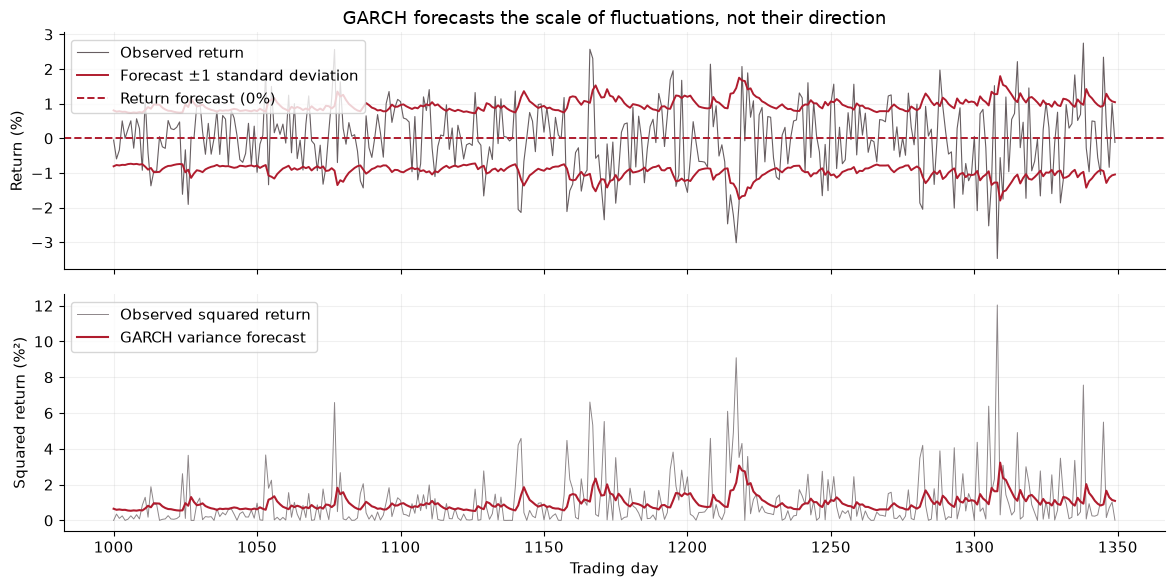

In [54]:
params, initial_var = fit_garch(returns[:N_TRAIN])
omega_hat, a_hat, b_hat = params
v_hat = garch_variance(returns, params, initial_var)

print(f"Fitted GARCH: omega = {omega_hat:.3f}, a = {a_hat:.3f}, b = {b_hat:.3f}")
print(f"Persistence a + b = {a_hat + b_hat:.3f}")

# Visualise the calm part of the test set, which the model has not trained on.
calm = slice(TEST_START, CRISIS_START)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.0), sharex=True)
axes[0].plot(days[calm], returns[calm], color=GREY, lw=0.8, label="Observed return")
sigma_hat = np.sqrt(v_hat)
axes[0].plot(days[calm], sigma_hat[calm], color=RED, lw=1.4, label="Forecast ±1 standard deviation")
axes[0].plot(days[calm], -sigma_hat[calm], color=RED, lw=1.4)
axes[0].axhline(0, color=RED, linestyle="--", lw=1.4, label="Return forecast (0%)")
axes[0].set(ylabel="Return (%)", title="GARCH forecasts the scale of fluctuations, not their direction")
axes[0].legend(loc="upper left")
axes[1].plot(days[calm], V[calm], color=GREY, lw=0.7, alpha=0.75, label="Observed squared return")
axes[1].plot(days[calm], v_hat[calm], color=RED, lw=1.5, label="GARCH variance forecast")
axes[1].set(xlabel="Trading day", ylabel="Squared return (%²)")
axes[1].legend(loc="upper left")
fig.tight_layout()
plt.show()

**Think about the plot.** The dashed red line marks the expected return of 0%, and the solid red lines show the forecasted scale of fluctuations. The lines $\pm\widehat\sigma_t$ are only model-based one-standard-deviation guides, not 90% conformal intervals. A good forecast of variance is not an accurate prediction of each individual squared return.

## 3. Classical conformal prediction in a calm market

We want an interval $C_t$ for the next squared return $V_t$ that contains the observed value about $90\%$ of the time. Fix the target miscoverage $\alpha=0.10$.

### 3.1. Calibrate the model's prediction errors

On the calibration days, measure the absolute difference between the realised squared return and the GARCH forecast:

$$s_j=|V_j-\widehat v_j|.$$

Larger scores indicate larger mistakes. We use the unnormalised score from the financial experiment of Gibbs & Candès (2024). The paper also studies a score divided by the forecasted variance, which often reduces the effect of changing volatility.

If we have $m$ calibration scores, sort them and take the order statistic at rank

$$k=\left\lceil (m+1)(1-\alpha)\right\rceil,\qquad q=s_{(k)}.$$

The finite-sample correction is standard in split conformal prediction. When $k>m$, use $q=+\infty$. Accept any non-negative candidate $v$ with $|v-\widehat v_t|\leq q$. Therefore,

$$C_t=[\max(0,\widehat v_t-q),\ \widehat v_t+q].$$

We intersect with the non-negative real line because a squared return cannot be negative. Notice that $q$ is the radius before this intersection.

**Important:** ordinary split conformal has a finite-sample marginal coverage guarantee under exchangeability (and a fixed fitted score function). GARCH data have temporal dependence, and our forecasts use the past sequentially. We therefore use this classical construction as an empirical baseline, not as a theorem guaranteeing 90% coverage for this time series. A calm regime is not the same as exchangeability.

Calibration sample size: 250
Corrected 90% score threshold: 2.031 percentage points squared
First test-day GARCH variance forecast: 0.651
First prediction interval: [0.000, 2.682] (%²)


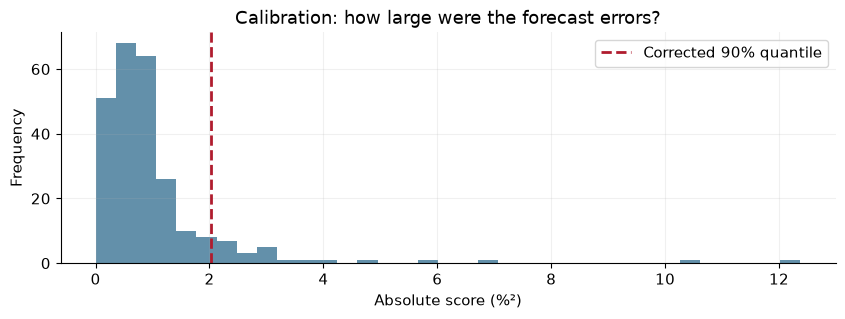

In [55]:
ALPHA = 0.10   # desired error rate; target coverage = 1 - ALPHA
scores = np.abs(V - v_hat)
cal_scores = scores[N_TRAIN:TEST_START]


def conformal_quantile(past_scores, alpha):
    """Corrected empirical quantile, including ACI's full/empty-set conventions."""
    if alpha <= 0:
        return np.inf       # accept every possible value
    if alpha >= 1:
        return -np.inf      # accept no possible value
    ordered = np.sort(past_scores)
    m = len(ordered)
    rank = int(np.ceil((m + 1) * (1 - alpha)))
    if rank > m:
        return np.inf
    return ordered[rank - 1]  # Python starts indexing at zero


def interval_bounds(forecast, radius):
    """Lower/upper endpoints; upper < lower represents an empty interval."""
    return np.maximum(0, forecast - radius), forecast + radius

q_fixed = conformal_quantile(cal_scores, ALPHA)
fixed_radii = np.full(N, q_fixed)
print(f"Calibration sample size: {len(cal_scores)}")
print(f"Corrected 90% score threshold: {q_fixed:.3f} percentage points squared")
print(f"First test-day GARCH variance forecast: {v_hat[TEST_START]:.3f}")
lo, hi = interval_bounds(v_hat[TEST_START], q_fixed)
print(f"First prediction interval: [{lo:.3f}, {hi:.3f}] (%²)")

fig, ax = plt.subplots(figsize=(10, 3.0))
ax.hist(cal_scores, bins=35, color=BLUE, alpha=0.72)
ax.axvline(q_fixed, color=RED, linestyle="--", lw=2, label="Corrected 90% quantile")
ax.set(title="Calibration: how large were the forecast errors?", xlabel="Absolute score (%²)", ylabel="Frequency")
ax.legend()
plt.show()

### 3.2. Plot the interval on unseen calm days

A dot outside the shaded region is a miscoverage event. The dashed/solid red forecast is the centre before truncation at zero. All subsequent interval plots use the same conventions. We use a symmetric-log vertical scale: it is linear near zero and compresses very large squared returns, making both calm and volatile periods visible. The values are still in squared percentage points.

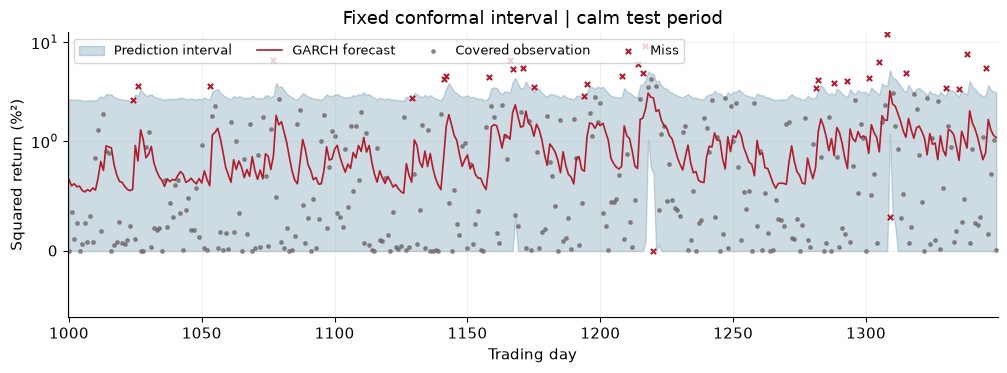

Target coverage: 90.0% | Observed calm-period coverage: 90.9%


In [56]:
def coverage_mask(radius):
    """At each day, did the realised squared return belong to the interval?"""
    return scores <= radius


def plot_intervals(ax, radii, start, stop, title, show_regimes=True):
    """Reusable chart: same data, GARCH forecast and prediction-set display."""
    idx = np.arange(start, stop)
    rad = radii[idx]
    low, high = interval_bounds(v_hat[idx], rad)
    # Only bounded, non-empty intervals can be drawn as finite shaded regions.
    finite = np.isfinite(rad) & (rad >= 0)
    ax.fill_between(idx, np.where(finite, low, np.nan),
                    np.where(finite, high, np.nan), color=BLUE, alpha=0.23,
                    label="Prediction interval")
    ax.plot(idx, v_hat[idx], color=RED, lw=1.2, label="GARCH forecast")
    hit = coverage_mask(radii)[idx]
    ax.scatter(idx[hit], V[idx][hit], s=6, color=GREY, alpha=0.65, label="Covered observation")
    ax.scatter(idx[~hit], V[idx][~hit], s=14, color=RED, marker="x", label="Miss")
    full = np.isposinf(rad)
    empty = np.isneginf(rad)
    if full.any():
        ax.scatter(idx[full], np.zeros(full.sum()), marker="^", color=TEAL, s=24,
                   label="Unbounded set (not shaded)")
    if empty.any():
        ax.scatter(idx[empty], np.zeros(empty.sum()), marker="v", color="black", s=24,
                   label="Empty set")
    if show_regimes:
        ax.axvspan(CRISIS_START-0.5, RECOVERY_START-0.5, color=RED, alpha=0.065)
        for boundary in [CRISIS_START, RECOVERY_START]:
            ax.axvline(boundary-0.5, color=GREY, linestyle="--", lw=0.8)
    ax.set(xlim=(start-0.5, stop-0.5), ylabel="Squared return (%²)", title=title)
    ax.set_yscale("symlog", linthresh=1)

fig, ax = plt.subplots(figsize=(12, 3.7))
plot_intervals(ax, fixed_radii, TEST_START, CRISIS_START,
               "Fixed conformal interval | calm test period", show_regimes=False)
ax.set_xlabel("Trading day")
ax.legend(ncol=4, loc="upper left", fontsize=9)
plt.show()

calm_coverage = coverage_mask(fixed_radii)[calm].mean()
print(f"Target coverage: {1-ALPHA:.1%} | Observed calm-period coverage: {calm_coverage:.1%}")

## 4. What if the market changes?

A financial crisis, an unexpected earnings announcement or a sudden shift in investors' expectations can alter the distribution of forecast errors. Our baseline GARCH model updates its conditional variance when it sees new returns, but the conformal threshold $q$ was calibrated in the past, during a calm regime.

**Question:** if errors become much larger, will the old threshold still provide 90% coverage? Run the next cell before reading the answer.

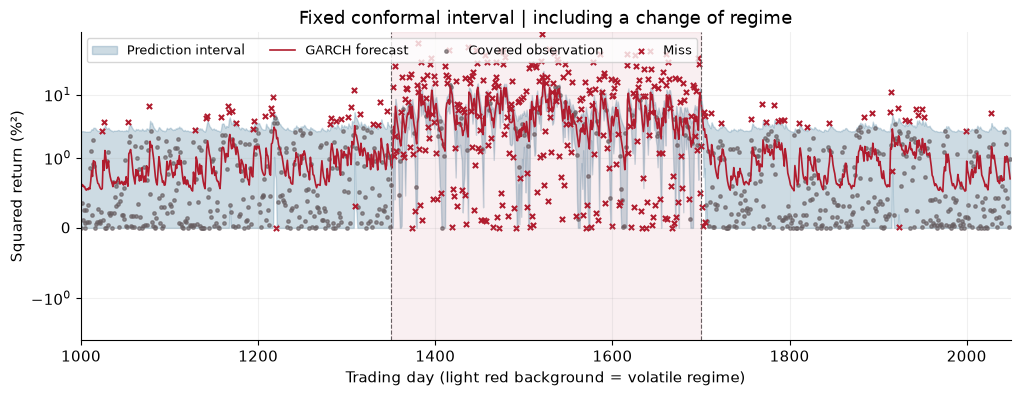

Calm coverage:   90.9%
Crisis coverage: 23.1%


In [57]:
fig, ax = plt.subplots(figsize=(12, 4.0))
plot_intervals(ax, fixed_radii, TEST_START, N,
               "Fixed conformal interval | including a change of regime")
ax.set_xlabel("Trading day (light red background = volatile regime)")
ax.legend(ncol=4, loc="upper left", fontsize=9)
plt.show()

crisis = slice(CRISIS_START, RECOVERY_START)
print(f"Calm coverage:   {coverage_mask(fixed_radii)[calm].mean():.1%}")
print(f"Crisis coverage: {coverage_mask(fixed_radii)[crisis].mean():.1%}")

The old threshold can be too small when the distribution of scores changes. This is a **distribution shift** problem. Even a model with a useful variance forecast may have poorly calibrated prediction intervals. Simply quoting the nominal 90% level does not tell us how the intervals actually perform under new conditions.

## 5. Adaptive conformal inference: learn from new errors

Gibbs & Candès (2024) study this problem in online settings, including stock-market volatility forecasting. We will implement the simpler **Adaptive Conformal Inference (ACI)** update from their 2021 work, with rolling calibration scores as in the financial example of the 2024 paper. Their more advanced DtACI method runs many ACI experts with different learning rates and dynamically aggregates them. We use just one learning rate so the mechanism is easy to understand.

### 5.1. Two ways to adapt

First, instead of using only a fixed historical calibration set forever, estimate the score quantile from the most recent $m=250$ observed errors:

$$q_t=\operatorname{Quantile}_{\rm corrected}\left(1-\alpha_t,\{s_{t-m},\ldots,s_{t-1}\}\right).$$

Second, let the calibration level $\alpha_t$ evolve. Start with $\alpha_1=\alpha=0.10$ at the beginning of the test period. At day $t$:

1. Use previous data to compute $\widehat v_t$ and $q_t$, and issue the prediction interval.
2. Observe $V_t$ at the end of that day. Define $e_t=\mathbf{1}_{\{V_t\notin C_t\}}$ (1 for a miss, 0 for a hit).
3. Update the calibration parameter for the **next** prediction:

$$\boxed{\alpha_{t+1}=\alpha_t+\gamma(\alpha-e_t).}$$

Here $\gamma>0$ is the learning rate. If the observation is missed, $\alpha_t$ decreases, requesting a higher score quantile and usually a wider interval. If the observation is covered, $\alpha_t$ increases slightly, requesting a lower quantile. The next interval also depends on the updated GARCH forecast and score window, so its actual width need not change monotonically.

**Example:** for $\gamma=0.01$ and $\alpha_t=0.10$, a miss gives $\alpha_{t+1}=0.091$; a hit gives $\alpha_{t+1}=0.101$. Our experiment uses $\gamma=0.007$ as an illustrative fixed choice, not an optimised or theoretically optimal value.

If $\alpha_t\leq0$ the set is the full non-negative real line; if $\alpha_t\geq1$ it is empty. We do not clip $\alpha_t$. An unbounded set can also occur at very small positive values because of the corrected rank. These edge cases are part of the implementation, not evidence of useful uncertainty estimates.

In [58]:
def online_conformal(scores, test_start, window, alpha, gamma):
    """Rolling quantiles with either fixed alpha (gamma=0) or ACI (gamma>0)."""
    n = len(scores)
    radii = np.full(n, np.nan)      # no online interval before the test starts
    alpha_history = np.full(n, np.nan)
    misses = np.full(n, np.nan)
    alpha_t = alpha

    for t in range(test_start, n):
        # BEFORE observing today's outcome: use only previous scores.
        past_scores = scores[t-window:t]
        alpha_history[t] = alpha_t
        radii[t] = conformal_quantile(past_scores, alpha_t)

        # AFTER observing today's outcome: check whether we missed it.
        misses[t] = int(scores[t] > radii[t])

        # Today's feedback is used only for tomorrow's calibration.
        alpha_t = alpha_t + gamma * (alpha - misses[t])

    return radii, alpha_history, misses


GAMMA = 0.007
# Same GARCH forecast, same initial scores, same test period for all methods.
rolling_radii, _, _ = online_conformal(scores, TEST_START, N_CAL, ALPHA, gamma=0)
aci_radii, alpha_history, aci_misses = online_conformal(scores, TEST_START, N_CAL, ALPHA, gamma=GAMMA)

# A small sanity check: at the first test day every method has the same inputs.
assert q_fixed == rolling_radii[TEST_START] == aci_radii[TEST_START]
assert np.all((aci_misses[TEST_START:] == 0) | (aci_misses[TEST_START:] == 1))
print(f"ACI learning rate: {GAMMA}")
print(f"Unbounded ACI prediction sets: {np.isposinf(aci_radii[TEST_START:]).sum()}")
print(f"Empty ACI prediction sets: {np.isneginf(aci_radii[TEST_START:]).sum()}")

ACI learning rate: 0.007
Unbounded ACI prediction sets: 0
Empty ACI prediction sets: 0


### 5.2. Visualise the adaptive method

The GARCH forecasts and observed returns are exactly the same as before. Only the uncertainty calibration changes. The lower plot shows how the internal calibration parameter moves in response to observed errors. The target error rate stays at 10%; $\alpha_t$ is an adjustable calibration parameter, not a new target probability.

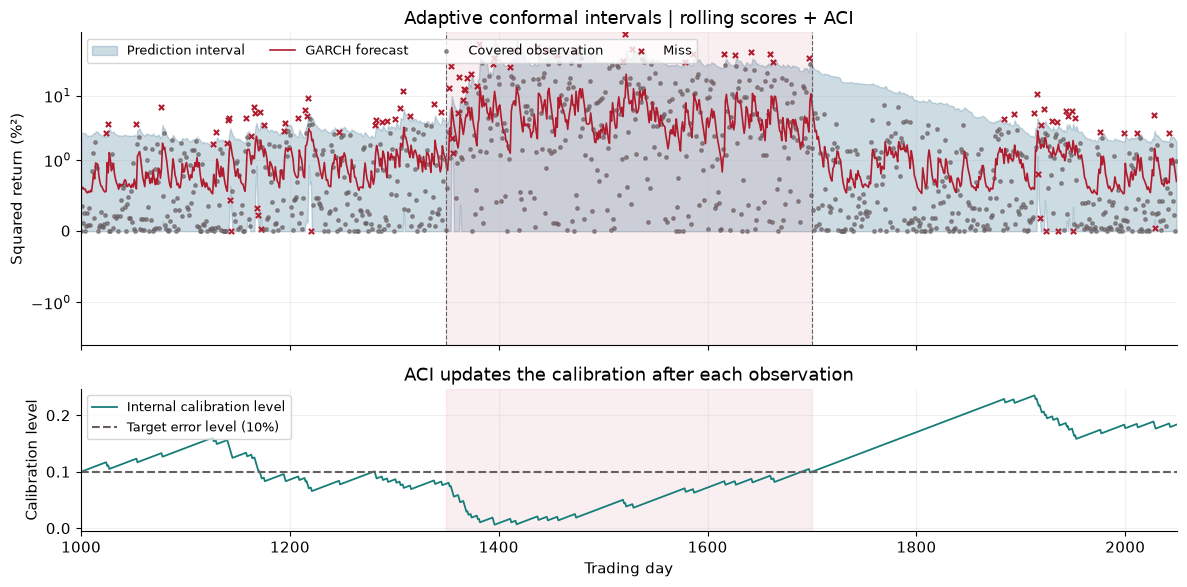

In [59]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.0), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})
plot_intervals(axes[0], aci_radii, TEST_START, N, "Adaptive conformal intervals | rolling scores + ACI")
axes[0].legend(ncol=4, loc="upper left", fontsize=9)
axes[1].plot(days[TEST_START:], alpha_history[TEST_START:], color=TEAL, lw=1.3,
             label="Internal calibration level")
axes[1].axhline(ALPHA, color=GREY, linestyle="--", label="Target error level (10%)")
axes[1].axvspan(CRISIS_START-0.5, RECOVERY_START-0.5, color=RED, alpha=0.065)
axes[1].set(xlabel="Trading day", ylabel="Calibration level", title="ACI updates the calibration after each observation")
axes[1].legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

## 6. Compare the methods: coverage is not the whole story

We compare three methods on exactly the same test observations:

**Fixed conformal:** uses the initial 250 calibration scores and fixed $\alpha=0.10$ throughout. **Rolling conformal:** updates the score window but keeps $\alpha_t=0.10$ fixed. **Adaptive conformal (ACI):** updates both the score window and $\alpha_t$. Including the middle method lets us distinguish the effect of recent data from the effect of feedback-based adaptation.

Empirical coverage measures the proportion of predictions that contain the realised value:

$$\widehat{\mathrm{Cov}}=\frac{1}{n}\sum_{t\in I}\mathbf{1}_{\{V_t\in C_t\}}.$$

We also measure interval width $|C_t|=U_t-L_t$ for bounded, non-empty intervals. Very wide intervals are less informative. An empty interval has width zero; an unbounded interval has infinite width. We report their counts separately and report median widths of finite sets, so that unbounded sets cannot silently masquerade as narrow intervals.

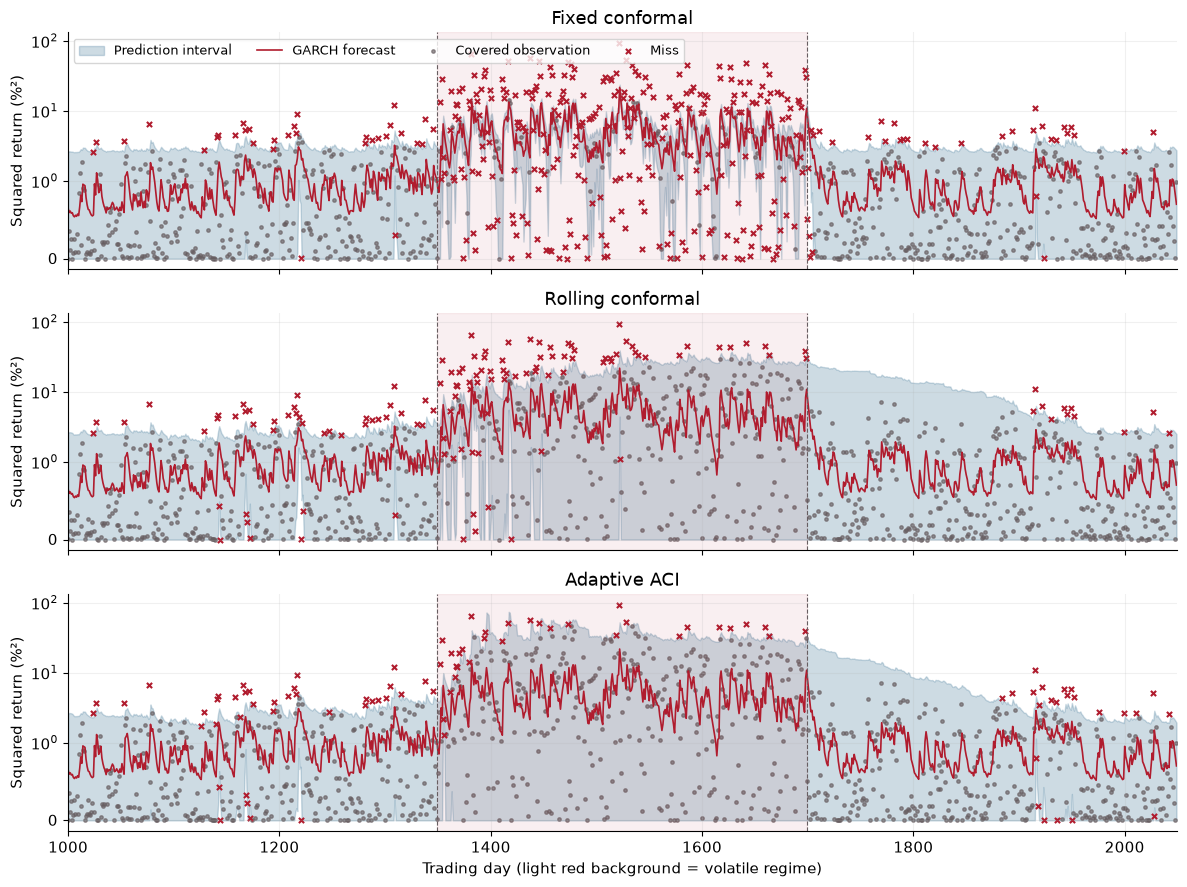

In [60]:
methods = {"Fixed conformal": fixed_radii,
           "Rolling conformal": rolling_radii,
           "Adaptive ACI": aci_radii}
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, (name, radii) in zip(axes, methods.items()):
    plot_intervals(ax, radii, TEST_START, N, name)
axes[0].legend(ncol=4, loc="upper left", fontsize=9)
axes[-1].set_xlabel("Trading day (light red background = volatile regime)")
fig.tight_layout()
plt.show()

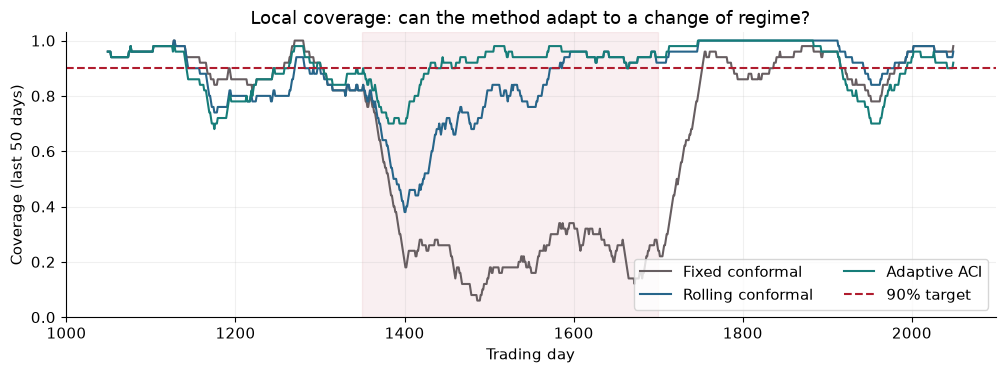

In [61]:
# Trailing (not centred) coverage: use the latest 50 test predictions.
# It is an evaluation diagnostic, not another forecast.
fig, ax = plt.subplots(figsize=(12, 3.7))
for (name, radii), colour in zip(methods.items(), [GREY, BLUE, TEAL]):
    hit = pd.Series(coverage_mask(radii)[TEST_START:].astype(float), index=days[TEST_START:])
    local_coverage = hit.rolling(50).mean()
    ax.plot(local_coverage.index, local_coverage, label=name, color=colour, lw=1.5)
ax.axhline(1-ALPHA, color=RED, linestyle="--", label="90% target")
ax.axvspan(CRISIS_START-0.5, RECOVERY_START-0.5, color=RED, alpha=0.065)
ax.set(xlabel="Trading day", ylabel="Coverage (last 50 days)", ylim=(0, 1.03),
       title="Local coverage: can the method adapt to a change of regime?")
ax.legend(ncol=2, loc="lower right")
plt.show()

In [62]:
# Summarise coverage and efficiency by regime, including the overall test period.
periods = {"Calm": (TEST_START, CRISIS_START),
           "Volatile": (CRISIS_START, RECOVERY_START),
           "Recovery": (RECOVERY_START, N),
           "All test days": (TEST_START, N)}
rows = []
for period, (start, stop) in periods.items():
    for name, radii in methods.items():
        rad = radii[start:stop]
        low, high = interval_bounds(v_hat[start:stop], rad)
        finite = np.isfinite(rad) & (rad >= 0)
        widths = high[finite] - low[finite]
        rows.append({"Period": period, "Method": name,
                     "Coverage": coverage_mask(radii)[start:stop].mean(),
                     "Median finite width (%²)": np.median(widths) if len(widths) else np.nan,
                     "Unbounded sets": int(np.isposinf(rad).sum()),
                     "Empty sets": int(np.isneginf(rad).sum())})
results = pd.DataFrame(rows)
display(results.style.format({"Coverage": "{:.1%}", "Median finite width (%²)": "{:.2f}"}))

,Period,Method,Coverage,Median finite width (%²),Unbounded sets,Empty sets
0,Calm,Fixed conformal,90.9%,2.90,0,0
1,Calm,Rolling conformal,87.7%,2.57,0,0
2,Calm,Adaptive ACI,89.1%,2.63,0,0
3,Volatile,Fixed conformal,23.1%,4.06,0,0
4,Volatile,Rolling conformal,78.6%,24.41,0,0
5,Volatile,Adaptive ACI,90.9%,32.65,0,0
6,Recovery,Fixed conformal,90.6%,2.91,0,0
7,Recovery,Rolling conformal,96.9%,8.52,0,0
8,Recovery,Adaptive ACI,93.4%,4.10,0,0
9,All test days,Fixed conformal,68.2%,3.17,0,0


### How to interpret the results

Compare the calm and volatile rows first. The fixed interval works reasonably well in the calm period but can miss many observations in the volatile regime. Rolling calibration helps, because it incorporates more recent errors. ACI further adjusts the nominal quantile using feedback and can bring the frequency of coverage closer to the target. In the recovery period, look for possible overcoverage: the calibration may take time to forget a turbulent period.

Also compare the widths. The adaptive method may need much wider intervals in the volatile regime. That is not automatically a problem: accurately communicating greater uncertainty is the objective. Nevertheless, an interval that is always extremely wide is not particularly useful. A good UQ method must balance **calibration and informativeness**.

The plots show one simulated path, not a universal empirical ranking of the algorithms. ACI has a simple long-run calibration property: when the update is used without clipping,

$$\frac{1}{T}\sum_{t=1}^T e_t=\alpha+\frac{\alpha_1-\alpha_{T+1}}{T\gamma}.$$

Since the full/empty-set conventions keep the state bounded, the average miscoverage approaches $\alpha$ as $T$ increases. This does **not** guarantee exact 90% coverage every day, within every regime, or conditional on a specific market state. The 2024 paper develops the more advanced DtACI to adapt the learning rate itself and studies local regret and coverage under additional conditions.

## 7. What can we do with this information in finance?

These are hypothetical examples of how to interpret an interval; no trading strategy is implemented.

**Example A — translate a variance-proxy interval into a risk communication.** Suppose tomorrow's prediction set for squared returns is $[0,4]$ in squared percentage points. Since $V_t=R_t^2$, this corresponds to $|R_t|\leq2\%$, or $R_t\in[-2\%,2\%]$. If the next day the interval becomes $[0,16]$, it corresponds to a move of up to 4% in either direction. An analyst can communicate that the range of plausible daily moves has widened. This is a prediction set for realised returns, not a confidence interval for the latent GARCH variance and not a one-sided VaR estimate.

**Example B — illustrate a simple risk budget.** Suppose a hypothetical unleveraged position has notional £100,000. A squared-return upper endpoint of 16 corresponds to an absolute daily price movement of 4%, or £4,000 in approximate P&L magnitude (exact for a simple return on a fixed position without other costs). If a hypothetical team uses £1,000 as its scenario-based movement budget, the illustrative exposure consistent with that bound is £1,000 / 0.04 = £25,000. This is a mechanical illustration, not a guarantee of maximum loss: moves outside the prediction set remain possible, the coverage is empirical and marginal, and actual portfolios can introduce leverage, liquidity and nonlinear exposures.

The key idea is that forecasting and uncertainty quantification are distinct: GARCH provides the baseline forecast; conformal calibration tells us how far realised outcomes may deviate from it.

## 8. Optional: try it yourself

Change `gamma_trial` below to a smaller or larger value. Before running the cell, predict what will happen after a shock. A small learning rate generally adjusts slowly; a large one can oscillate, request extremely high quantiles and sometimes create unbounded or empty prediction sets.

Learning rate: 0.03
Volatile-period coverage: 90.6%
Unbounded sets: 18
Empty sets: 0


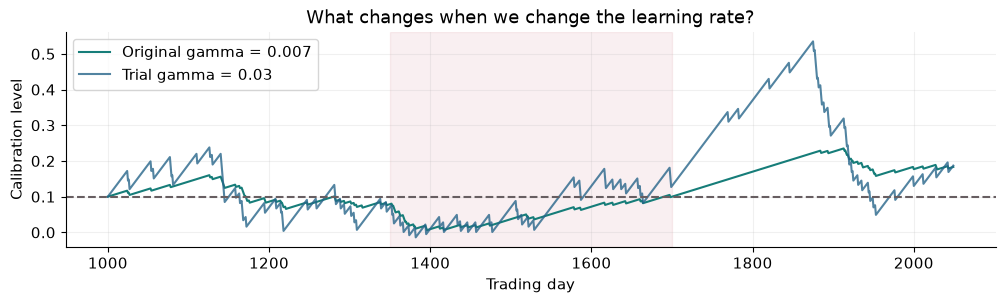

In [63]:
# Try 0.001, 0.007, 0.03, or 0.08. This does not refit GARCH.
gamma_trial = 0.03
trial_radii, trial_alpha, _ = online_conformal(scores, TEST_START, N_CAL, ALPHA, gamma_trial)
print(f"Learning rate: {gamma_trial}")
print(f"Volatile-period coverage: {coverage_mask(trial_radii)[crisis].mean():.1%}")
print(f"Unbounded sets: {np.isposinf(trial_radii[TEST_START:]).sum()}")
print(f"Empty sets: {np.isneginf(trial_radii[TEST_START:]).sum()}")
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.plot(days[TEST_START:], alpha_history[TEST_START:], color=TEAL, label=f"Original gamma = {GAMMA}")
ax.plot(days[TEST_START:], trial_alpha[TEST_START:], color=BLUE, alpha=0.8, label=f"Trial gamma = {gamma_trial}")
ax.axhline(ALPHA, color=GREY, linestyle="--")
ax.axvspan(CRISIS_START-0.5, RECOVERY_START-0.5, color=RED, alpha=0.065)
ax.set(xlabel="Trading day", ylabel="Calibration level", title="What changes when we change the learning rate?")
ax.legend()
plt.show()

**Takeaway.** Uncertainty is not necessarily stationary. A prediction set calibrated on yesterday's data may be misleading tomorrow. Sequential feedback allows us to adapt the calibration without replacing the underlying predictive model.